<a href="https://colab.research.google.com/github/alokchoudharyguliya/Applied-Accelerated-AI/blob/main/Week5_TF_Acceleration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

After 200 steps:
W=2.0000 (target:2.0)
b=2.0000 (target:1.0)
Final loss=0.00000


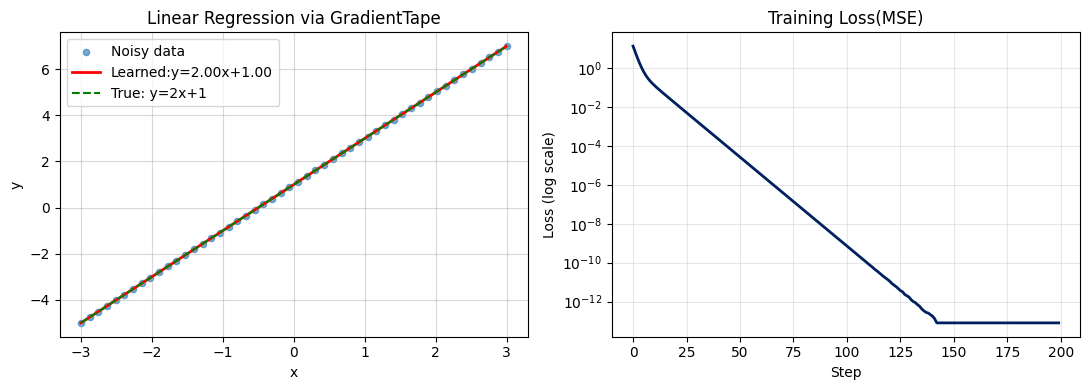

Figure saved.


In [11]:
np.random.seed(42)
x_train=tf.constant(np.linspace(-3,3,50),dtype=tf.float32)
y_train=tf.constant(2.0*x_train+1.0+np.random.randn(50)*0.,dtype=tf.float32)

W=tf.Variable(0.0,name="weight")
b=tf.Variable(0.0,name='bias')
optimizer=tf.optimizers.SGD(learning_rate=0.05)

losses=[]
for step in range(200):
  with tf.GradientTape() as tape:
    y_pred=W*x_train+b
    loss=tf.reduce_mean(tf.square(y_pred-y_train))
  grads=tape.gradient(loss,[W,b])
  optimizer.apply_gradients(zip(grads,[W,b]))
  losses.append(loss.numpy())
print("After 200 steps:")
print(f"W={W.numpy():.4f} (target:2.0)")
print(f"b={W.numpy():.4f} (target:1.0)")
print(f"Final loss={losses[-1]:.5f}")

# Plot
fig, (ax1, ax2)=plt.subplots(1,2,figsize=(11,4))
ax1.scatter(x_train.numpy(),y_train.numpy(),s=20,alpha=0.6, label="Noisy data")
x_line=np.linspace(-3,3,100)
ax1.plot(x_line, W.numpy()*x_line+b.numpy(), 'r-',lw=2,label=f'Learned:y={W.numpy():.2f}x+{b.numpy():.2f}')
ax1.plot(x_line,2*x_line+1,'g--',lw=1.5,label='True: y=2x+1')
ax1.legend();

ax1.set_title('Linear Regression via GradientTape')
ax1.set_xlabel('x');ax1.set_ylabel('y');ax1.grid(alpha=0.5)

ax2.semilogy(losses,color='#002060',lw=2)
ax2.set_title('Training Loss(MSE)');ax2.set_xlabel('Step');ax2.set_ylabel('Loss (log scale)')
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("lec1_regression.png",dpi=100,bbox_inches='tight')
plt.show()
print("Figure saved.")

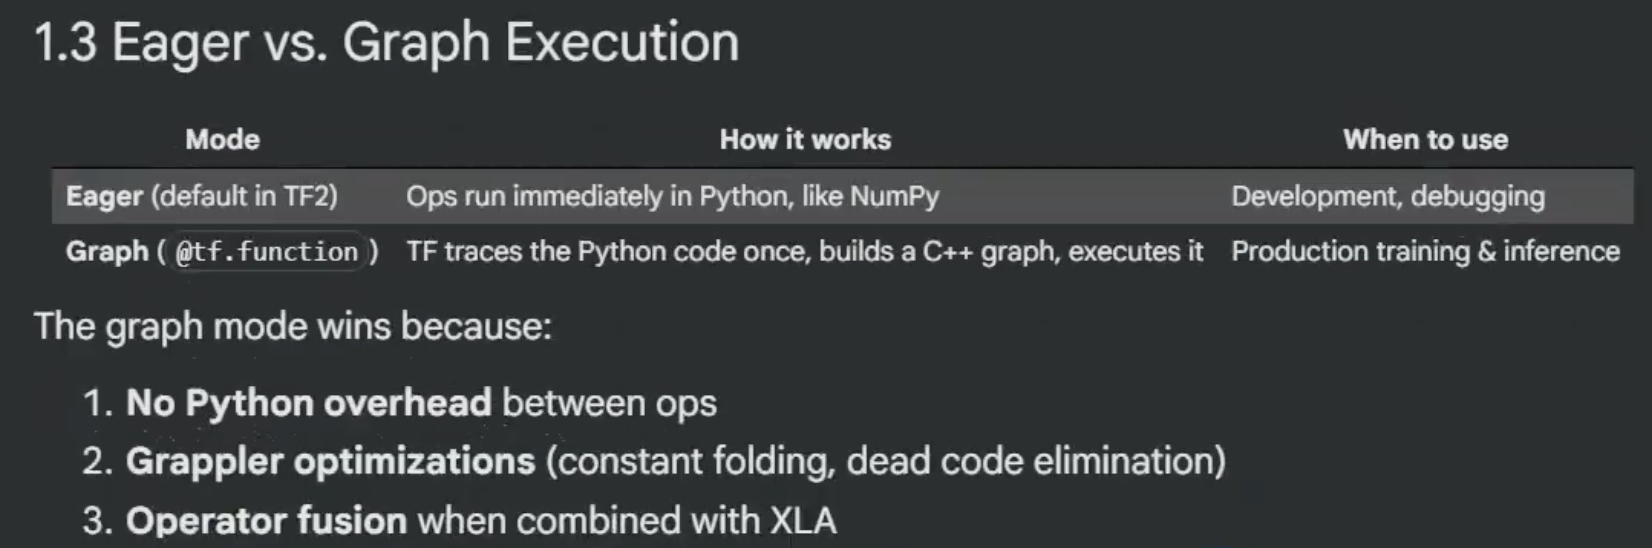

In [ ]:
# ---- 1.5 Eager vs Graph Execution Benchmark ----
def heavy_computation(x):
  """
  A compute-heavy sequence of ops
  """
  for _ in range(10):
    x=tf.matmul(x,x)
    y=tf.nn.relu(x)
  return x

# Compiled(graph) version
heavy_graph=tf.function(heavy_computation)
data=tf.random.normal([32,32])

# Warm0up: triggers graph tracing on firsst call
_=heavy_graph(data)
N=20
# Time eager

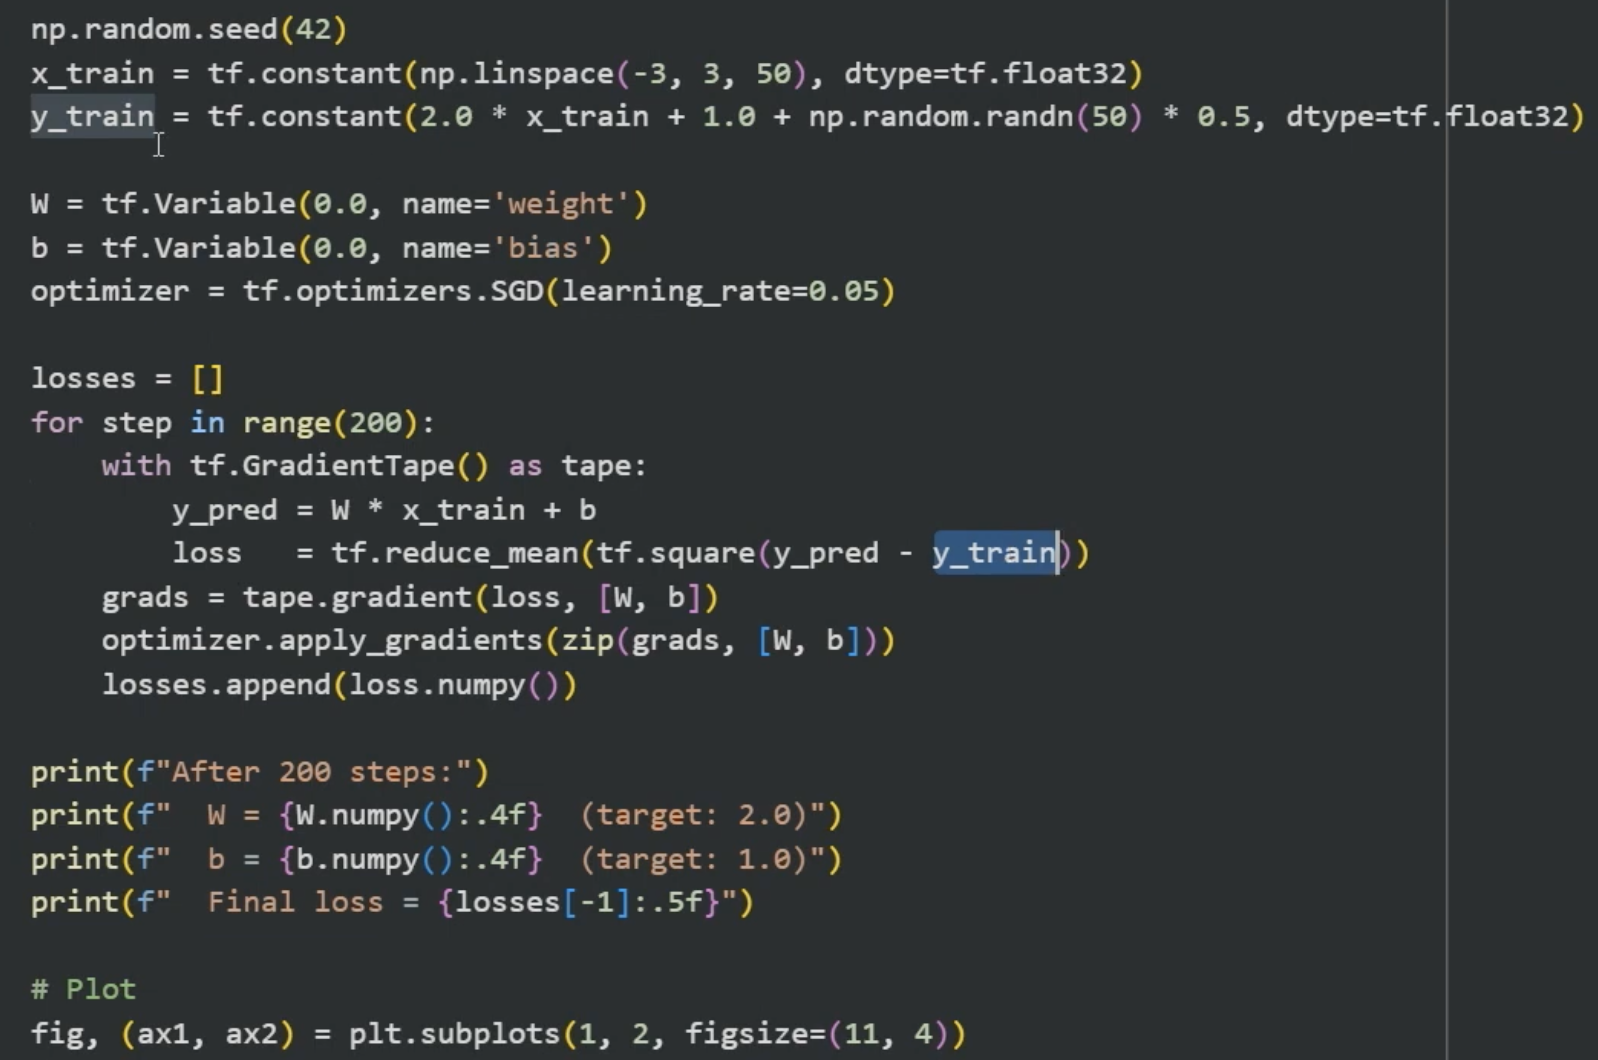